In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
import skdim
import scipy

from scipy.stats import gaussian_kde
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[2]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values)

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                     keepdims=True)) / np.std(z,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])

Randomly selected eid: Data2/cc45c568-c3b9-4f74-836e-c87762e898c8
cosmos
CNU          315
HPF          125
HY            79
Isocortex    529
MB           308
TH           187
root          81
dtype: int64


Components needed for 95.0% variance: 13


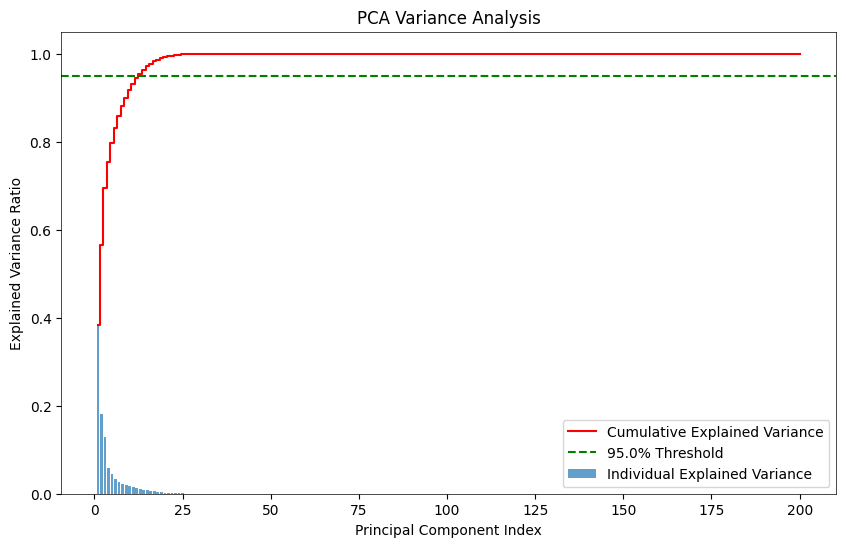

Denoising complete.


In [6]:

#########################################################################
############### Calculate linear dimension and denoise  #################
#########################################################################
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def denoise_with_pca(data, variance_threshold=0.95):
    # 1. Scale the data (Crucial for PCA)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    # 2. Fit PCA to determine variance distribution
    pca = PCA()
    pca.fit(scaled_data)

    # Calculate cumulative variance
    exp_var_ratio = pca.explained_variance_ratio_
    cum_var_ratio = np.cumsum(exp_var_ratio)

    # 3. Find the number of components needed for threshold (e.g., 95%)
    n_components = np.argmax(cum_var_ratio >= variance_threshold) + 1
    print(f"Components needed for {variance_threshold*100}% variance: {n_components}")

    # 4. Plotting the Fraction of Variance Explained
    plt.figure(figsize=(10, 6))
    plt.bar(range(1, len(exp_var_ratio) + 1), exp_var_ratio, alpha=0.7,
            label='Individual Explained Variance')
    plt.step(range(1, len(cum_var_ratio) + 1), cum_var_ratio, where='mid',
             label='Cumulative Explained Variance', color='red')
    plt.axhline(y=variance_threshold, color='green', linestyle='--',
                label=f'{variance_threshold*100}% Threshold')
    plt.xlabel('Principal Component Index')
    plt.ylabel('Explained Variance Ratio')
    plt.title('PCA Variance Analysis')
    plt.legend(loc='best')
    plt.show()

    # 5. Denoise by Reconstructing with reduced components
    pca_reduced = PCA(n_components=n_components)
    projected = pca_reduced.fit_transform(scaled_data)
    reconstructed = pca_reduced.inverse_transform(projected)

    # Inverse transform the scaling to get back to original units
    denoised_data = scaler.inverse_transform(reconstructed)

    return denoised_data, n_components

noisy_data = response_matrix.T
denoised_x, comps = denoise_with_pca(noisy_data)
print("Denoising complete.")

In [7]:
############### Calculate intrinsic dimension of denoised data #################
fisher = skdim.id.FisherS().fit(denoised_x )
id_fisher = fisher.dimension_
print(f"FisherS Estimator: {id_fisher:.2f}")


FisherS Estimator: 4.47


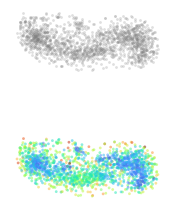

In [8]:
#########################################################################
############### Initial TSNE plot colored by gain       #################
#########################################################################

fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])

data_snr = []
for neuron in range(responses.shape[2]):
    means = []
    for t in range(99):
        h = (responses[:, t + 1, neuron] - responses[:, t, neuron]) / (responses[:, t, neuron] + 10)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))

x_proj = TSNE(n_components = 2,perplexity = 200).fit_transform(response_matrix.T)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data_snr,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [81]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll
class Permutation(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.perm = torch.randperm(dim)
        self.inv_perm = torch.argsort(self.perm)

    def forward(self, x):
        return x[:, self.perm], 0 # No log-det change for permutation



# --- 1. RealNVP Coupling Layer (Architecture remains the same) ---
class CouplingLayer(nn.Module):
    def __init__(self, dim, hidden_dim, mask):
        super().__init__()
        self.mask = mask
        self.scale_net = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, dim), nn.Tanh()
        )
        self.trans_net = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, dim)
        )

    def forward(self, x):
        x1 = x * self.mask
        s = self.scale_net(x1) * (1 - self.mask)
        t = self.trans_net(x1) * (1 - self.mask)
        y = x1 + (1 - self.mask) * (x * torch.exp(s) + t)
        log_det = torch.sum(s, dim=1)
        return y, log_det

class AlternatingMFlow(nn.Module):
    def __init__(self, D, d, hidden_dim=256, num_layers=8):
        super().__init__()
        self.D = D
        self.d = d
        # In your MDFlow __init__:
        self.layers = nn.ModuleList()
        for i in range(num_layers):
            self.layers.append(Permutation(D)) # Mix dims
            mask = torch.zeros(D)
            mask[:D//2] = 1
            if i % 2 == 0: mask = 1 - mask # Flip mask every other layer
            self.layers.append(CouplingLayer(D, hidden_dim, mask))

    def forward(self, x):
        log_det_total = 0
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_total += log_det
        return z, log_det_total

# --- 2. Setup Data ---
n_neurons = 2000
D = 200
d = 2
# X_raw, _ = make_swiss_roll(n_samples=n_neurons, noise=0.05)
# X_high_d = np.zeros((n_neurons, D))
# X_high_d[:, :3] = X_raw
# X_high_d += np.random.normal(0, 0.01, size=(n_neurons, D))
X_tensor = torch.FloatTensor(response_matrix.T)

# --- 3. Alternating Training Strategy ---
model = AlternatingMFlow(D=D, d=d)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

epochs = 1000
m_steps = 1 # Steps for density estimation
d_steps = 100 # Steps for manifold learning (often needs more focus early on)

print("Starting Alternating M/D Training...")

for epoch in range(epochs):
    # --- D-STEP: Manifold Learning ---
    # Goal: Minimize the energy in the discarded dimensions (u)
    for _ in range(d_steps):
        optimizer.zero_grad()
        z_full, _ = model(X_tensor)
        u = z_full[:, d:]
        loss_d = torch.mean(torch.sum(u**2, dim=1))
        loss_d.backward()
        optimizer.step()

    # --- M-STEP: Density Estimation ---
    # Goal: Maximize log-likelihood on the manifold dimensions (z)
    for _ in range(m_steps):
        optimizer.zero_grad()
        z_full, log_det = model(X_tensor)
        z = z_full[:, :d]

        # Log-likelihood on manifold
        log_pz = -0.5 * torch.sum(z**2, dim=1) - 0.5 * d * np.log(2 * np.pi)
        loss_m = -(log_pz + log_det).mean()

        loss_m.backward()
        optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch:4} | D-Loss: {loss_d.item():.6f} | M-Loss: {loss_m.item():.2f}")



Starting Alternating M/D Training...
Epoch    0 | D-Loss: 1.209160 | M-Loss: -303.96


KeyboardInterrupt: 

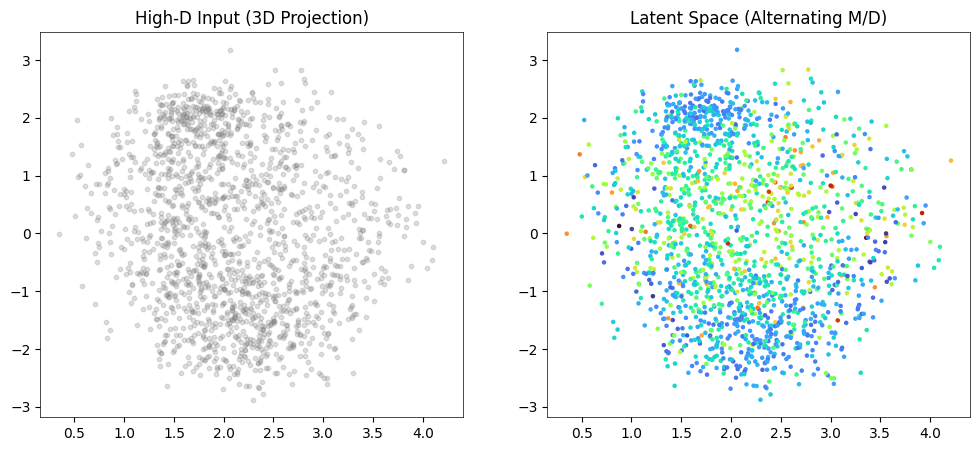

In [82]:
# --- 4. Plotting Results ---
model.eval()
with torch.no_grad():
    z_full, _ = model(X_tensor)
    z_latents = z_full[:, :d].numpy()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(z_latents[:, 0], z_latents[:, 1], color='gray', s=10,alpha = .25)
plt.title("High-D Input (3D Projection)")

plt.subplot(1, 2, 2)
plt.scatter(z_latents[:, 0], z_latents[:, 1], c=data_snr, cmap='turbo', s=5)
plt.title("Latent Space (Alternating M/D)")
plt.show()

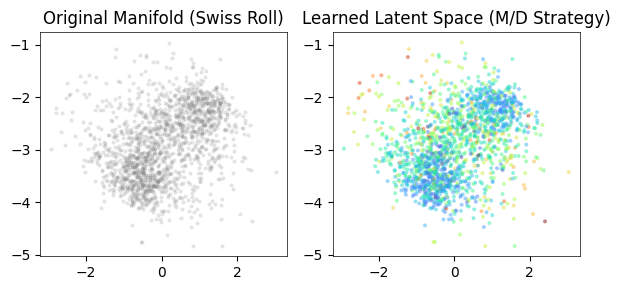

In [48]:
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.scatter(z_latents[:, 0], z_latents[:, 1], color='gray', alpha =.15, s=4)
plt.title("Original Manifold (Swiss Roll)")

plt.subplot(1, 2, 2)
plt.scatter(z_latents[:, 0], z_latents[:, 1], c=data_snr, cmap='turbo', s=4,alpha = .35)
plt.title("Learned Latent Space (M/D Strategy)")
plt.tight_layout()
plt.show()

In [ ]:
# Riemannian flow

In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.datasets import make_s_curve
from nflows.flows.base import Flow
from nflows.distributions.normal import StandardNormal
from nflows.transforms.autoregressive import MaskedAffineAutoregressiveTransform
#from nflows.transforms.composites import CompositeTransform

# --- 1. Dataset Setup ---
n_samples = 2000
data, color = make_s_curve(n_samples, noise=0.1)
data = torch.tensor(data, dtype=torch.float32)

# --- 2. Model Architecture ---
class ManifoldEncoder(nn.Module):
    """ The 'M' in M/D: Projects Data -> Latent Space """
    def __init__(self, input_dim=3, latent_dim=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
    def forward(self, x):
        return self.net(x)

def build_density_estimator(latent_dim=2):
    """ The 'D' in M/D: Normalizing Flow on the Latent Space """
    transitions = []
    for _ in range(3):
        transitions.append(MaskedAffineAutoregressiveTransform(
            features=latent_dim, hidden_features=32))
    transform = CompositeTransform(transitions)
    distribution = StandardNormal(shape=[latent_dim])
    return Flow(transform, distribution)

# --- 3. M/D Training Strategy ---
encoder = ManifoldEncoder()
density_flow = build_density_estimator()

optimizer_m = optim.Adam(encoder.parameters(), lr=1e-3)
optimizer_d = optim.Adam(density_flow.parameters(), lr=1e-3)

epochs = 500
batch_size = 128

for epoch in range(epochs):
    # Shuffle
    idx = torch.randperm(n_samples)
    data_shuffled = data[idx]

    for i in range(0, n_samples, batch_size):
        x = data_shuffled[i:i+batch_size]

        # --- M-Step: Manifold Learning (Contrastive or Reconstruction) ---
        # Here we use a simplified distance-preserving objective
        optimizer_m.zero_grad()
        z = encoder(x)
        # Loss: Maintain local distances (Isometric approximation)
        dist_x = torch.pdist(x[:32])
        dist_z = torch.pdist(z[:32])
        loss_m = nn.MSELoss()(dist_z, dist_x)
        loss_m.backward()
        optimizer_m.step()

        # --- D-Step: Density Learning ---
        optimizer_d.zero_grad()
        with torch.no_grad():
            z_fixed = encoder(x).detach()
        # Maximize log-likelihood of latent codes
        loss_d = -density_flow.log_prob(inputs=z_fixed).mean()
        loss_d.backward()
        optimizer_d.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch} | M-Loss: {loss_m.item():.4f} | D-Loss: {loss_d.item():.4f}")

# --- 4. Visualization ---
with torch.no_grad():
    latent_coords = encoder(data).numpy()

fig = plt.figure(figsize=(12, 5))

# Plot Original 3D Manifold
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(data[:, 0], data[:, 1], data[:, 2], c=color, cmap='viridis')
ax1.set_title("Original 3D Manifold (S-Curve)")

# Plot 2D Latent Distribution
ax2 = fig.add_subplot(122)
scatter = ax2.scatter(latent_coords[:, 0], latent_coords[:, 1], c=color, cmap='viridis')
ax2.set_title("Learned 2D Latent Distribution (M-Flow)")
plt.colorbar(scatter, ax=ax2)

plt.tight_layout()
plt.show()

NameError: name 'CompositeTransform' is not defined

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from openTSNE import TSNE

# 1. Create a synthetic dataset with clusters of different densities
# Cluster 0: Dense, Cluster 1: Sparse
data = response_matrix.T
labels = data_snr

# 2. Run standard t-SNE (Standard comparison)
tsne_standard = TSNE(random_state=42).fit(data)

# 3. Run densSNE (Density-preserving)
# We set densmap=True to preserve local density
tsne_dense = TSNE(
    random_state=42,
    densmap=True,
    dens_lambda=0.1  # Strength of density preservation
).fit(data)

# 4. Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(tsne_standard[:, 0], tsne_standard[:, 1], c=labels, s=5, alpha=0.6)
ax1.set_title("Standard t-SNE\n(Clusters look similar in size)")

ax2.scatter(tsne_dense[:, 0], tsne_dense[:, 1], c=labels, s=5, alpha=0.6)
ax2.set_title("densSNE\n(Preserves relative cluster density)")

plt.show()

TypeError: __init__() got an unexpected keyword argument 'densmap'

Dimensions after PCA (95% variance): 13


<Axes: >

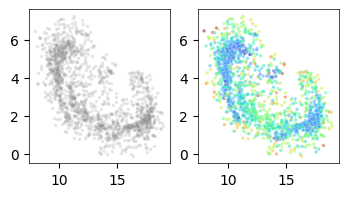

In [108]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import Normalizer
import matplotlib.pyplot as plt

def lambert_equal_area_projection(data):
    """
    Projects n-dimensional spherical data to (n-1) dimensions
    using an Equal Area mapping.
    """
    n_samples, n_dim = data.shape
    x = data[:, :-1]
    z = data[:, -1]

    # Lambert scaling factor: sqrt(2 / (1 - z))
    scale = np.sqrt(2 / (1 - z + 1e-9))
    return x * scale[:, np.newaxis]

# 1. Generate high-dimensional dummy data (e.g., 50 dimensions)
n_samples = 1000
#raw_data = np.random.randn(n_samples, 50)
raw_data = response_matrix.T
# 2. PCA: Explain 95% of the variance
# This reduces the 50 dimensions down to the 'n' components that matter most.
pca = PCA(n_components=0.95)
pca_data = pca.fit_transform(raw_data)
print(f"Dimensions after PCA (95% variance): {pca_data.shape[1]}")

# 3. Spherical Normalization
# The Equal Area mapping requires data to lie on a unit sphere.
# PCA outputs Euclidean coordinates, so we project them to the surface of a sphere.
normalizer = Normalizer(norm='l2')
spherical_data = normalizer.transform(pca_data)

# 4. Apply Lambert Equal Area Mapping
# This maps the n-dimensional sphere data to (n-1) dimensions.
projected_data = lambert_equal_area_projection(spherical_data)

# 5. Apply t-SNE for final 2D visualization
# tsne = TSNE(n_components=2, perplexity=400, learning_rate='auto', init='pca', random_state=42)
# tsne_results = tsne.fit_transform(projected_data)

fit = umap.UMAP(densmap=True,dens_lambda =1,n_neighbors= 100)
tsne_results= fit.fit_transform(response_matrix.T)

# 6. Visualization
fig = plt.figure(figsize=(4,2))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,2)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
sns.scatterplot(x = tsne_results[:, 0], y = tsne_results[:, 1], alpha=0.2, color='gray',ax=ax0,s=6)
sns.scatterplot(x = tsne_results[:, 0], y = tsne_results[:, 1],alpha=0.5, hue = data_snr,palette='turbo',ax=ax1,s=6,legend = False)


Training on cpu...
Epoch 000 | Loss: 4.5719 | DensLoss: 59.6108
Epoch 050 | Loss: 0.6347 | DensLoss: 9.9689
Epoch 100 | Loss: 0.6189 | DensLoss: 10.7414
Epoch 150 | Loss: 0.6064 | DensLoss: 10.9387
Epoch 200 | Loss: 0.5962 | DensLoss: 11.1086
Epoch 250 | Loss: 0.5829 | DensLoss: 11.1346
Epoch 300 | Loss: 0.5791 | DensLoss: 11.1146
Epoch 350 | Loss: 0.5717 | DensLoss: 11.1185
Epoch 400 | Loss: 0.5668 | DensLoss: 11.0273
Epoch 450 | Loss: 0.5719 | DensLoss: 10.8737
Epoch 500 | Loss: 0.5693 | DensLoss: 11.0902
Epoch 550 | Loss: 0.5634 | DensLoss: 11.3315
Epoch 600 | Loss: 0.5621 | DensLoss: 11.2150
Epoch 650 | Loss: 0.5639 | DensLoss: 11.1930
Epoch 700 | Loss: 0.5564 | DensLoss: 11.1275
Epoch 750 | Loss: 0.5645 | DensLoss: 11.1811
Epoch 800 | Loss: 0.5565 | DensLoss: 11.3777
Epoch 850 | Loss: 0.5543 | DensLoss: 11.2147
Epoch 900 | Loss: 0.5634 | DensLoss: 11.1582
Epoch 950 | Loss: 0.5635 | DensLoss: 11.1046
Epoch 1000 | Loss: 0.5597 | DensLoss: 11.3088
Epoch 1050 | Loss: 0.5544 | DensLoss

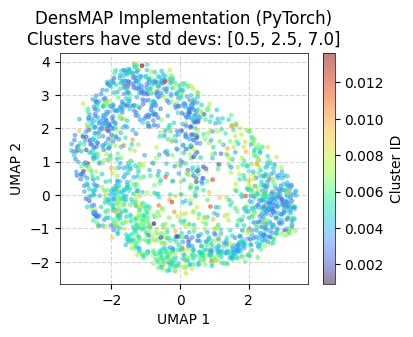

In [103]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_blobs
import numpy as np

# 1. Model Definition
class DenseParametricUMAP(nn.Module):
    def __init__(self, input_dim, output_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.encoder(x)

# 2. Training Logic
def train_dens_umap(data, labels, n_neighbors=15, epochs=300, d_alpha=0.2):
    n_samples, input_dim = data.shape
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --- Pre-processing ---
    nn_search = NearestNeighbors(n_neighbors=n_neighbors).fit(data)
    distances, indices = nn_search.kneighbors(data)

    # High-dim local radii (log-mean distance to neighbors)
    high_dim_radii = torch.tensor(np.log(distances[:, 1:].mean(axis=1) + 1e-8), dtype=torch.float32).to(device)

    # Graph edges
    rows = np.repeat(np.arange(n_samples), n_neighbors)
    cols = indices.flatten()

    x_tensor = torch.tensor(data, dtype=torch.float32).to(device)
    model = DenseParametricUMAP(input_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=2e-3)

    print(f"Training on {device}...")
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        embeddings = model(x_tensor)
        pos_i, pos_j = embeddings[rows], embeddings[cols]
        dist_sq = torch.sum((pos_i - pos_j)**2, dim=1)

        # 1. Attraction Loss
        q_ij = 1.0 / (1.0 + dist_sq)
        attraction = -torch.log(q_ij + 1e-8).mean()

        # 2. Repulsion Loss (prevents collapse)
        # We sample random pairs for negative edges
        random_indices = torch.randint(0, n_samples, (len(rows),))
        neg_dist_sq = torch.sum((embeddings[rows] - embeddings[random_indices])**2, dim=1)
        repulsion = -torch.log(1.0 - (1.0 / (1.0 + neg_dist_sq)) + 1e-8).mean()

        # 3. Density Preservation Loss
        low_dim_radii = torch.log(dist_sq.view(n_samples, n_neighbors).mean(dim=1) + 1e-8)
        density_loss = torch.mean((high_dim_radii - low_dim_radii)**2)

        loss = attraction + repulsion + (d_alpha * density_loss)

        loss.backward()
        optimizer.step()

        if epoch % 50 == 0:
            print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | DensLoss: {density_loss.item():.4f}")

    return model

# 3. Execution and Plotting
if __name__ == "__main__":
    # Generate data: 3 clusters with wildly different densities
    # Cluster 1: tight (0.5), Cluster 2: medium (2.0), Cluster 3: sparse (5.0)
    stds = [0.5, 2.5, 7.0]
   # X, y = make_blobs(n_samples=1200, n_features=50, centers=3, cluster_std=stds, random_state=42)
    X = torch.FloatTensor(response_matrix.T)
    y = torch.FloatTensor(data_snr)
    # Train
    model = train_dens_umap(X, y, epochs=3000, d_alpha=0)

    # Project
    model.eval()
    with torch.no_grad():
        coords = model(torch.tensor(X, dtype=torch.float32)).cpu().numpy()

    # Plotting
    plt.figure(figsize=(4, 3))
    scatter = plt.scatter(coords[:, 0], coords[:, 1], c=y, cmap='turbo', s=6, alpha=0.5)
    plt.colorbar(scatter, label='Cluster ID')
    plt.title("DensMAP Implementation (PyTorch)\nClusters have std devs: [0.5, 2.5, 7.0]")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.grid(True, linestyle='--', alpha=0.5)

    print("\nDisplaying plot...")
    plt.show()

In [90]:
import numpy as np
import tensorflow as tf
from umap.parametric_umap import ParametricUMAP

# 1. Generate or Load your data
# Using a synthetic dataset for demonstration
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=2000, noise=0.05)
X = response_matrix.T

# 2. Define the Neural Network Architecture (The Encoder)
# This is the "Deep" part of the Deep DensMAP
encoder = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X.shape[1],)),
    tf.keras.layers.Dense(units=100, activation="relu"),
    tf.keras.layers.Dense(units=100, activation="relu"),
    tf.keras.layers.Dense(units=100, activation="relu"),
    tf.keras.layers.Dense(units=2), # Output layer for 2D projection
])

# 3. Initialize Parametric DensMAP
# Setting densmap=True is the key parameter here
embedder = ParametricUMAP(
    encoder=encoder,
    dims=(X.shape[1],),
    densmap=True,         # Enables density preservation
    n_neighbors=30,
    verbose=True
)

# 4. Train the network
# The model will optimize the UMAP loss + the density preservation loss
embedding = embedder.fit_transform(X)

# 5. Using the model for new data
# Since it's a DNN, you can now project unseen points instantly
# new_projections = encoder.predict(new_data)

ImportError: cannot import name 'clip_to_image_size' from 'keras.src.layers.preprocessing.image_preprocessing.bounding_boxes.converters' (/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/keras/src/layers/preprocessing/image_preprocessing/bounding_boxes/converters.py)